In [28]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay, roc_auc_score, average_precision_score)
from sklearn.model_selection import StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import matplotlib.pyplot as plt

train = pd.read_parquet("../data/processed/train_fe.parquet")
test = pd.read_parquet("../data/processed/test_fe.parquet")
print(train.shape, test.shape)

(26064, 13) (6517, 13)


In [29]:
NUMERIC = [
    "person_age", "person_income", "person_emp_length", "loan_amnt",
    "cb_person_cred_hist_length", "loan_to_income_ratio",
]
CATEGORICAL = ["person_home_ownership", "loan_intent", "cb_person_default_on_file"]
FEATURES = NUMERIC + CATEGORICAL

def make_preprocessor():
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("num", numeric, NUMERIC),
        ("cat", categorical, CATEGORICAL),
    ])

In [30]:
X_train, y_train = train[FEATURES], train["loan_status"]
X_test, y_test = test[FEATURES], test["loan_status"]

models = {
    "Dummy": DummyClassifier(strategy="prior"),
    "Logistic": LogisticRegression(max_iter=1500, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1),
}

def make_pipeline(model):
    return Pipeline([("preprocessor", make_preprocessor()), ("model", model)])

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []

for name, model in models.items():
    scores = cross_validate(
        make_pipeline(model),
        X_train,
        y_train,
        cv=cv,
        scoring={"ap": "average_precision", "roc_auc": "roc_auc"},
        n_jobs=-1,
    )
    results.append(
        {
            "model": name,
            "cv_ap": scores["test_ap"].mean(),
            "cv_roc_auc": scores["test_roc_auc"].mean(),
        }
    )
comparison = pd.DataFrame(results).sort_values("cv_ap", ascending=False)
print(comparison)

           model     cv_ap  cv_roc_auc
2  Random Forest  0.775872    0.870930
1       Logistic  0.623157    0.809473
0          Dummy  0.218155    0.500000


: 

In [32]:
search = RandomizedSearchCV(
    estimator=make_pipeline(RandomForestClassifier(random_state=42, n_jobs=-1)),
    param_distributions={
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [None, 8, 16],
        "model__min_samples_leaf": [1, 3, 5],
        "model__max_features": ["sqrt", 0.8],
    },
    n_iter=8,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    random_state=42,
    refit=True,
)
search.fit(X_train, y_train)
print("Best CV average precision:", round(search.best_score_, 4))
print("Best parameters:", search.best_params_)

Best CV average precision: 0.7947
Best parameters: {'model__n_estimators': 300, 'model__min_samples_leaf': 5, 'model__max_features': 0.8, 'model__max_depth': None}


In [33]:
best_baseline = comparison.iloc[0]
if search.best_score_ > best_baseline["cv_ap"]:
    final_model = search.best_estimator_
    chosen_name = "Tuned Random Forest"
else:
    chosen_name = best_baseline["model"]
    final_model = make_pipeline(models[chosen_name])
    final_model.fit(X_train, y_train)
print("Selected:", chosen_name)

Selected: Tuned Random Forest


Holdout ROC-AUC: 0.8848
Holdout average precision: 0.801
              precision    recall  f1-score   support

           0       0.89      0.99      0.93      5095
           1       0.91      0.55      0.69      1422

    accuracy                           0.89      6517
   macro avg       0.90      0.77      0.81      6517
weighted avg       0.89      0.89      0.88      6517



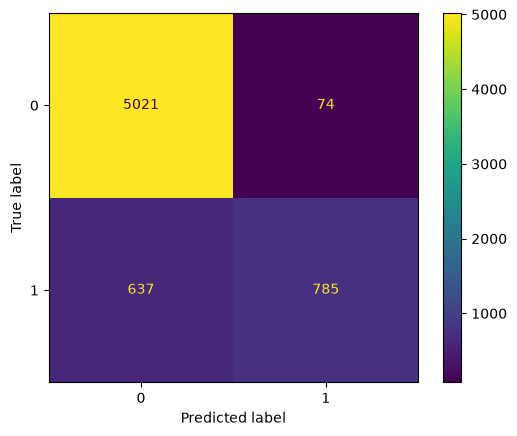

In [34]:
proba = final_model.predict_proba(X_test)[:, 1]
pred = final_model.predict(X_test)
print("Holdout ROC-AUC:", round(roc_auc_score(y_test, proba), 4))
print("Holdout average precision:", round(average_precision_score(y_test, proba), 4))
print(classification_report(y_test, pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.show()

In [35]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, pred))

[[5021   74]
 [ 637  785]]


In [38]:
from pathlib import Path
import joblib
Path("../models").mkdir(exist_ok=True)
joblib.dump(final_model, "../models/credit_risk_pipeline.joblib")


['../models/credit_risk_pipeline.joblib']